## Model 3 compiled into circuits, and two-stage DB-DOI for Models 2 and 3

This notebook does for Model 3 what `Example_3` and `Example_7` did for Models 1 and 2, and adds the "two-stage DB-DOI" left open in `RESULTS_Model_2.md`:
1. the compiled evolution oracle of $H(\vec B^*)$ (8 qubits, the field point at the centre of the `Example_9` sweep): Trotter error, exact CNOT count and depth;
2. DB-DOI ground-state preparation on the full 8-qubit Hamiltonian, with the ideal oracle and a compiled replay;
3. **two-stage DB-DOI**: circuit-level preparation of the lowest state inside the 4-qubit block isolated by matrix-level DBQA, for the Z1 hyperfine block of Model 3 and the $^4I_{15/2}$ block of Model 2, with explicit compiled circuits.

**What the two-stage variant assumes.** The block is $P\,U^\dagger H U P$, with $U$ the stage-A rotation found at matrix level, so its oracle is a 4-qubit Hamiltonian known classically. That is the setting in which the 4-qubit circuits are meaningful (for example as a subroutine after a classical compression). Preparing the same state from the full Hamiltonian on hardware would also need $U$ as a circuit, which is part 2.

DB-DOI uses `GroupCommutatorIteration` with the reduced group commutator, as in the earlier notebooks; a step of duration $s$ evolves for $\sqrt s$. The notebook takes about 30 minutes.

In [1]:
import os

os.environ["OPENBLAS_NUM_THREADS"] = "2"

import logging
import pickle
import sys
import time
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.sparse.csgraph import connected_components

from qibo import gates, hamiltonians, set_backend
from qibo.config import log
from qibo.symbols import Z

from pycf.import_sljm import ImportSLJM

from qibo_dbqa.utils_crystal_field import *

sys.path.append(os.path.abspath("../../src"))
from db_doi.group_commutator_iteration import GroupCommutatorIteration, DoubleBracketRotationApproximationType

os.environ.setdefault("PYCF_ROOT", os.path.abspath("../../../pycf"))
set_backend("numpy")
log.setLevel(logging.ERROR)
os.makedirs("pdfs_figures", exist_ok=True)
os.makedirs("simulation_results", exist_ok=True)

with open("simulation_results/Er_YSO_DBQA_L_8.pickle", "rb") as file:
    sweep_data = pickle.load(file)
sweep = sweep_data["sweep"]
model = hyperfine_field_model(ImportSLJM(pycf_matel_path("erhfs", "eryso")), er_yso_pycf_coeff(hyperfine=ER_YSO_SITE2_HYPERFINE_JOBBITT2021))
UNIT = 5000.0
padded, nqubits, _ = embed_in_qubits(linear_field_hamiltonian(model["h0"], field_operators(model), sweep["field"]))
h_matrix = (padded - np.trace(padded).real / 256 * np.eye(256)) / UNIT
energies, vectors = np.linalg.eigh(h_matrix)
decomposition = pauli_decomposition(h_matrix)
print(f"H(B*): {nqubits} qubits, {len(decomposition)} Pauli strings, spectral norm {np.max(np.abs(energies)):.3f}")


def oracle_queries(circuit, n):
    return sum(1 for g in circuit.queue if isinstance(g, gates.Unitary) and len(g.qubits) == n)


def run_doi(oracle, reference, d_candidates, step_grid, nsteps, report, n):
    gci = GroupCommutatorIteration(
        h=oracle,
        preparation_circuit=basis_state_circuit(n, reference),
        double_bracket_rotation_approximation_type=DoubleBracketRotationApproximationType.group_commutator_reduced,
    )
    history = [dict(report(gci.preparation_circuit), queries=0, step=None, d=None)]
    for k in range(nsteps):
        start = time.time()
        best = None
        for j, d in enumerate(d_candidates):
            s, loss, _, _ = gci.choose_step(d, step_grid=step_grid)
            if best is None or loss < best[1]:
                best = (s, loss, j)
        gci(best[0], d_candidates[best[2]])
        history.append(dict(report(gci.preparation_circuit), queries=oracle_queries(gci.preparation_circuit, n), step=best[0], d=best[2]))
        print(f"   k={k + 1}: s={best[0]:.3g}, D #{best[2]}, " + ", ".join(f"{key}={value:.3g}" for key, value in history[-1].items() if key not in ("queries", "step", "d"))
              + f", queries={history[-1]['queries']} ({time.time() - start:.0f} s)", flush=True)
    return history

[Qibo 0.2.14|INFO|2026-10-17 10:27:52]: Using numpy backend on /CPU:0


H(B*): 8 qubits, 5977 Pauli strings, spectral norm 0.992


#### 1. Compiled oracle of $H(\vec B^*)$

Error of $n$ Trotter–Suzuki steps of size $\delta t$ against $e^{-it H}$ at $t = n\,\delta t = 1$, the longest evolution DB-DOI uses with $s \le 1$; CNOT counts and depths are exact for the compiled CNOT-ladder circuits (`compiled_trotter_unitary`, `compiled_trotter_depth`).

In [2]:
traceless = h_matrix - decomposition.get("I" * nqubits, 0.0) * np.eye(256)
exact_1 = expm(-1j * traceless)
trotter_table = []
start = time.time()
print(f"{'order':>5s} {'steps':>5s} {'error at t=1':>13s} {'CNOT':>9s} {'depth':>9s}")
for ts_order, steps_list in ((1, (1, 4, 16)), (2, (1, 2, 4, 8, 16))):
    for n in steps_list:
        step = compiled_trotter_unitary(decomposition, 1.0 / n, ts_order)
        error = np.linalg.norm(np.linalg.matrix_power(step, n) - exact_1, 2)
        row = dict(ts_order=ts_order, steps=n, error=error, cnot=n * trotter_cnot_count(decomposition, ts_order), depth=compiled_trotter_depth(decomposition, ts_order, n))
        trotter_table.append(row)
        print(f"{ts_order:5d} {n:5d} {error:13.1e} {row['cnot']:9d} {row['depth']:9d}")
accurate = [r for r in trotter_table if r["ts_order"] == 2 and r["error"] <= 5e-3]
chosen = min(accurate, key=lambda r: r["steps"]) if accurate else min(trotter_table, key=lambda r: r["error"])
TROTTER_STEPS = chosen["steps"]
oracle_cnot, oracle_depth = chosen["cnot"], chosen["depth"]
print(f"oracle: second order, {TROTTER_STEPS} steps (error {chosen['error']:.1e} at t = 1), {oracle_cnot} CNOTs and depth {oracle_depth} per call ({time.time() - start:.0f} s)")

order steps  error at t=1      CNOT     depth


    1     1       2.2e-02     55530     70739


    1     4       5.6e-03    222120    282920


    1    16       1.4e-03    888480   1131644


    2     1       2.7e-03    111048    141465


    2     2       6.7e-04    222096    282930


    2     4       1.7e-04    444192    565860


    2     8       4.2e-05    888384   1131720


    2    16       1.0e-05   1776768   2263440
oracle: second order, 1 steps (error 2.7e-03 at t = 1), 111048 CNOTs and depth 141465 per call (28 s)


#### 2. DB-DOI on the full 8-qubit Hamiltonian

Reference: the basis state with the lowest diagonal entry. Diagonal operators: $\pm\sum_i Z_i$ and $\pm Z_i$ (18 candidates), durations on 20 points in $[10^{-3}, 1]$ as in `Example_7`, 5 steps with the ideal oracle. (The longer grid of `Example_12` was not used here: this run already peaks near 19 GB of memory, from the deep-copied circuits of up to 121 oracle calls.) We record the energy above the ground state, the fidelity with the lowest hyperfine state of Z1, and the weight on the 16 Z1 states and on the 128 $^4I_{15/2}$ states.

In [3]:
z1_states = vectors[:, :16]
multiplet_states = vectors[:, :128]


def report_full(circuit):
    state = circuit().state()
    energy = np.real(state.conj() @ h_matrix @ state)
    return dict(dE_cm=UNIT * (energy - energies[0]), infidelity_ground=1 - abs(vectors[:, 0].conj() @ state) ** 2,
                leak_Z1=1 - np.sum(np.abs(z1_states.conj().T @ state) ** 2), leak_4I15=1 - np.sum(np.abs(multiplet_states.conj().T @ state) ** 2))


fields = [np.ones(nqubits), -np.ones(nqubits)] + [s * np.eye(nqubits)[i] for i in range(nqubits) for s in (1, -1)]
d_full = [hamiltonians.SymbolicHamiltonian(sum(float(b) * Z(q) for q, b in enumerate(f) if b != 0), nqubits=nqubits) for f in fields]
reference_full = int(np.argmin(np.real(np.diag(h_matrix))))
print(f"reference |{reference_full}>:", report_full(basis_state_circuit(nqubits, reference_full)))
history_full = run_doi(ExactEvolutionHamiltonian(h_matrix), reference_full, d_full, np.linspace(1e-3, 1.0, 20), 5, report_full, nqubits)

reference |120>: {'dE_cm': 143.70728914001762, 'infidelity_ground': 0.9989069298457434, 'leak_Z1': 0.9299561349218086, 'leak_4I15': 0.00013381602786355362}


   k=1: s=0.79, D #4, dE_cm=140, infidelity_ground=0.999, leak_Z1=0.925, leak_4I15=0.000112, queries=1 (4 s)


   k=2: s=0.842, D #4, dE_cm=137, infidelity_ground=0.999, leak_Z1=0.921, leak_4I15=0.000102, queries=4 (5 s)


   k=3: s=0.842, D #4, dE_cm=134, infidelity_ground=0.999, leak_Z1=0.916, leak_4I15=8.99e-05, queries=13 (8 s)


   k=4: s=0.895, D #4, dE_cm=131, infidelity_ground=0.999, leak_Z1=0.911, leak_4I15=8.39e-05, queries=40 (19 s)


   k=5: s=0.842, D #4, dE_cm=128, infidelity_ground=0.999, leak_Z1=0.906, leak_4I15=8.38e-05, queries=121 (49 s)


In [4]:
compiled = GroupCommutatorIteration(
    h=CompiledUnitaryHamiltonian(h_matrix, trotter_steps=TROTTER_STEPS, ts_order=2),
    preparation_circuit=basis_state_circuit(nqubits, reference_full),
    double_bracket_rotation_approximation_type=DoubleBracketRotationApproximationType.group_commutator_reduced,
)
replay_full = []
for k in range(2):
    r = history_full[k + 1]
    compiled(r["step"], d_full[r["d"]])
    replay_full.append(report_full(compiled.preparation_circuit))
    print(f"compiled replay k={k + 1}: dE = {replay_full[-1]['dE_cm']:.4f} cm^-1 (ideal {r['dE_cm']:.4f}), 1-F ground {replay_full[-1]['infidelity_ground']:.4e} (ideal {r['infidelity_ground']:.4e})")
print(f"\n{'k':>2s} {'dE (cm^-1)':>11s} {'1-F ground':>11s} {'leak Z1':>9s} {'leak 4I15/2':>11s} {'queries':>8s} {'CNOT':>12s}")
for k, r in enumerate(history_full):
    print(f"{k:2d} {r['dE_cm']:11.2f} {r['infidelity_ground']:11.4f} {r['leak_Z1']:9.2e} {r['leak_4I15']:11.2e} {r['queries']:8d} {r['queries'] * oracle_cnot:12d}")

compiled replay k=1: dE = 140.6066 cm^-1 (ideal 140.4499), 1-F ground 9.9884e-01 (ideal 9.9884e-01)


compiled replay k=2: dE = 137.6224 cm^-1 (ideal 137.2872), 1-F ground 9.9878e-01 (ideal 9.9878e-01)

 k  dE (cm^-1)  1-F ground   leak Z1 leak 4I15/2  queries         CNOT
 0      143.71      0.9989  9.30e-01    1.34e-04        0            0
 1      140.45      0.9988  9.25e-01    1.12e-04        1       111048
 2      137.29      0.9988  9.21e-01    1.02e-04        4       444192
 3      134.15      0.9987  9.16e-01    8.99e-05       13      1443624
 4      131.12      0.9986  9.11e-01    8.39e-05       40      4441920
 5      128.33      0.9986  9.06e-01    8.38e-05      121     13436808


#### 3. Two-stage DB-DOI inside the isolated 4-qubit blocks

**Blocks.** Model 3: the Z1 block at $\vec B^*$ captured at $1-F<10^{-9}$ in `Example_9`. Model 2: the $^4I_{15/2}$ block captured at $1-F<10^{-6}$ (group-commutator stage 1 of `Example_5`, recomputed here). Each block is shifted to zero trace and divided by its spectral norm.

**DB-DOI.** Reference: the lowest-diagonal basis state of the block within the symmetry sector that contains its lowest level. The stage-A rotation is built from evolutions under $H$ and under diagonal operators, so the sectors of Model 2 survive in its block, and DB-DOI with Z-field generators cannot leave the sector of its reference (`RESULTS_Model_2.md` §5.3); Model 3 has a single sector. Diagonal operators: the 16 magnetic fields $\sum_i b_i Z_i$, $b_i = \pm1$, as for Model 1 (`Example_3`). Durations: 40 log-spaced points in $[10^{-3}, 10^2]$ (the lessons of `Example_11` and `Example_12`), 8 steps with the ideal oracle. The target is the lowest level of the block: the lowest hyperfine state of Z1 (Model 3), the ground Kramers doublet (Model 2).

**Compiled circuits.** The oracle is the second-order Trotter circuit with the fewest steps whose error at $t = 10$ (the longest evolution, $\sqrt{100}$) is below $5\times10^{-3}$; the first three DB-DOI steps are built as explicit circuits.

In [5]:
def block_doi(block, ground_indices, label, unit_label, scale):
    shifted = block - np.trace(block).real / 16 * np.eye(16)
    unit = np.max(np.abs(np.linalg.eigvalsh(shifted)))
    b = shifted / unit
    e, v = np.linalg.eigh(b)
    target = v[:, ground_indices]

    def report(circuit):
        state = circuit().state()
        return dict(dE=scale * unit * (np.real(state.conj() @ b @ state) - e[0]), infidelity=1 - np.sum(np.abs(target.conj().T @ state) ** 2))

    fields4 = [np.array([1 - 2 * x for x in bits], dtype=float) for bits in np.ndindex(*(2,) * 4)]
    d4 = [hamiltonians.SymbolicHamiltonian(sum(x * Z(q) for q, x in enumerate(f)), nqubits=4) for f in fields4]
    # symmetry sectors survive the stage-A rotation (it is built from evolutions under H and under diagonal D), and
    # DB-DOI with Z-field D never leaves the sector of its reference state (RESULTS_Model_2.md, section 5.3): take the
    # lowest-diagonal basis state of the sector that contains the lowest level
    n_sectors, sector_of = connected_components(np.abs(b) > 1e-9 * np.max(np.abs(b)), directed=False)
    sector_minima = [np.min(np.linalg.eigvalsh(b[np.ix_(sector_of == c, sector_of == c)])) for c in range(n_sectors)]
    members = np.nonzero(sector_of == int(np.argmin(sector_minima)))[0]
    reference = int(members[np.argmin(np.real(np.diag(b))[members])])
    print(f"{label}: {n_sectors} sector(s) of sizes {np.bincount(sector_of).tolist()}; block gap above the target {scale * unit * (e[len(ground_indices)] - e[0]):.4g} {unit_label}; reference |{reference:04b}>: {report(basis_state_circuit(4, reference))}")
    history = run_doi(ExactEvolutionHamiltonian(b), reference, d4, np.logspace(-3, 2, 40), 8, report, 4)
    t_max = np.sqrt(max(r["step"] for r in history[1:]))
    exact = expm(-1j * t_max * b)
    for n in (1, 2, 4, 8, 16, 32, 64, 128):
        # the block is traceless, so the compiled circuit has no dropped global phase
        oracle = PauliCompiledHamiltonian(b, trotter_steps=n, ts_order=2)
        error = np.linalg.norm(oracle.circuit(t_max).unitary() - exact, 2)
        if error <= 5e-3:
            break
    circuit = oracle.circuit(0.1)
    cnot_per_call, depth_per_call = two_qubit_gate_count(circuit), circuit.depth
    print(f"   oracle: second order, {n} steps, error {error:.1e} at t = {t_max:.2f}; {cnot_per_call} CNOTs, depth {depth_per_call} per call")
    gci = GroupCommutatorIteration(h=deepcopy(oracle), preparation_circuit=basis_state_circuit(4, reference),
                                   double_bracket_rotation_approximation_type=DoubleBracketRotationApproximationType.group_commutator_reduced)
    compiled_history = []
    for k in range(3):
        r = history[k + 1]
        gci(r["step"], d4[r["d"]])
        c = gci.preparation_circuit
        compiled_history.append(dict(report(c), cnot=two_qubit_gate_count(c), depth=c.depth, step=r["step"], d=r["d"]))
        print(f"   compiled k={k + 1}: dE {compiled_history[-1]['dE']:.4g} {unit_label} (ideal {r['dE']:.4g}), 1-F {compiled_history[-1]['infidelity']:.3e} (ideal {r['infidelity']:.3e}), "
              f"CNOT {compiled_history[-1]['cnot']}, depth {compiled_history[-1]['depth']}")
    return dict(history=history, compiled=compiled_history, trotter_steps=n, cnot_per_call=cnot_per_call, depth_per_call=depth_per_call,
                unit=unit, block=b, reference=reference, ground_indices=ground_indices, d_fields=fields4)


k_mid = int(np.argmin(np.abs(sweep["magnitudes"] - np.linalg.norm(sweep["field"]))))
block3 = sweep_data["cold"][k_mid]["captured"][1e-9]["block"]
two_stage = {"Model 3": block_doi(block3, [0], "Model 3, Z1 block at B*", "MHz", CM_TO_MHZ)}

Model 3, Z1 block at B*: 1 sector(s) of sizes [16]; block gap above the target 851.3 MHz; reference |1000>: {'dE': 12271.770658185002, 'infidelity': 0.9831765137363865}


   k=1: s=0.492, D #4, dE=2.52e+03, infidelity=0.974, queries=1 (1 s)


   k=2: s=100, D #12, dE=1.73e+03, infidelity=0.902, queries=4 (2 s)


   k=3: s=100, D #8, dE=1.43e+03, infidelity=0.706, queries=13 (4 s)


   k=4: s=0.113, D #0, dE=1.16e+03, infidelity=0.697, queries=40 (11 s)


...

   k=8: s=12.7, D #2, dE=426, infidelity=0.256, queries=3280 (889 s)


   oracle: second order, 128 steps, error 3.2e-03 at t = 10.00; 259840 CNOTs, depth 432512 per call


   compiled k=1: dE 2524 MHz (ideal 2524), 1-F 9.743e-01 (ideal 9.743e-01), CNOT 259840, depth 432516


   compiled k=2: dE 1734 MHz (ideal 1733), 1-F 9.018e-01 (ideal 9.017e-01), CNOT 1039360, depth 1730064


   compiled k=3: dE 1428 MHz (ideal 1427), 1-F 7.068e-01 (ideal 7.064e-01), CNOT 3377920, depth 5622708


In [6]:
f11cf = ImportSLJM(pycf_matel_path("f11cf", "eryso"))
coeff2 = er_liyf4_pycf_coeff(ER_LIYF4_FREE_ION_REFIT)
h2, _ = crystal_field_hamiltonian([getattr(f11cf, n) for n in coeff2], coeff2, energy_unit=20000.0)
m2 = h2.backend.to_numpy(h2.matrix)
manifolds2 = group_levels(np.linalg.eigvalsh(m2), 300.0 / 20000.0)
stage1 = run_dbqa_history(m2, "group commutator", dict(manifolds=manifolds2), 150, np.logspace(-4, 1, 100), capture=("manifolds", 0, (1e-6,)), stop_when_captured=True)
k2, matrix2 = stage1["captured"][1e-6]
index2 = np.sort(np.argsort(np.real(np.diag(matrix2)))[:16])
block2 = matrix2[np.ix_(index2, index2)] * 20000.0
print(f"Model 2 stage 1 reaches 1-F < 1e-6 at iteration {k2}")
two_stage["Model 2"] = block_doi(block2, [0, 1], "Model 2, 4I15/2 block", "cm^-1", 1.0)

/home/aarush_das_bansiwal/micromamba/envs/dbqa-cf/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model 2 stage 1 reaches 1-F < 1e-6 at iteration 16
Model 2, 4I15/2 block: 4 sector(s) of sizes [4, 4, 4, 4]; block gap above the target 0.3862 cm^-1; reference |0110>: {'dE': 99.85606010928653, 'infidelity': 0.9498375731115072}


   k=1: s=0.492, D #3, dE=6.57, infidelity=0.928, queries=1 (1 s)


   k=2: s=0.273, D #3, dE=5.54, infidelity=0.925, queries=4 (2 s)


   k=3: s=100, D #4, dE=5.27, infidelity=0.881, queries=13 (4 s)


...

   k=8: s=100, D #4, dE=1.95, infidelity=0.314, queries=3280 (933 s)


   oracle: second order, 64 steps, error 3.8e-03 at t = 10.00; 12160 CNOTs, depth 21184 per call


   compiled k=1: dE 6.566 cm^-1 (ideal 6.566), 1-F 9.275e-01 (ideal 9.275e-01), CNOT 12160, depth 21191


   compiled k=2: dE 5.54 cm^-1 (ideal 5.54), 1-F 9.247e-01 (ideal 9.247e-01), CNOT 48640, depth 84761


   compiled k=3: dE 5.271 cm^-1 (ideal 5.272), 1-F 8.809e-01 (ideal 8.809e-01), CNOT 158080, depth 275471


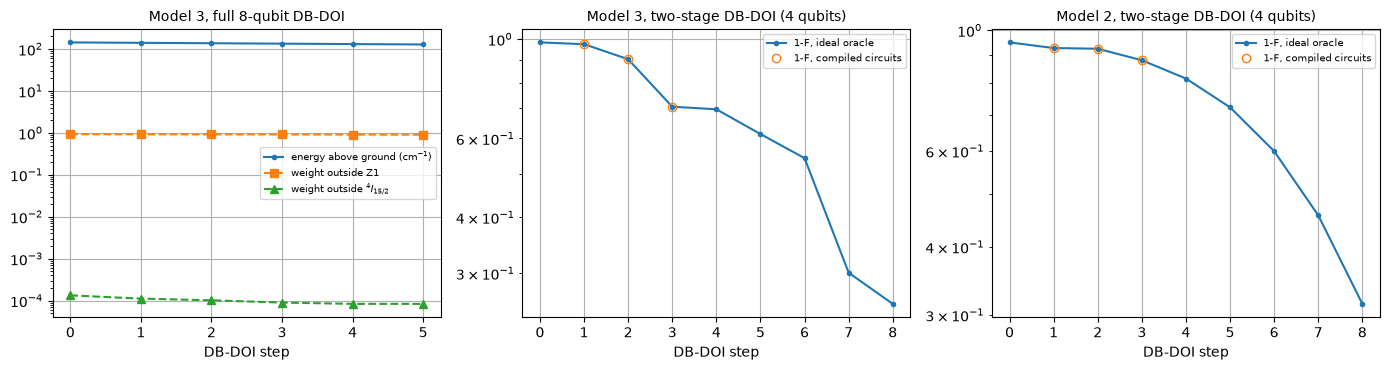

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
ks = np.arange(len(history_full))
axes[0].semilogy(ks, [r["dE_cm"] for r in history_full], ".-", label="energy above ground (cm$^{-1}$)")
axes[0].semilogy(ks, [r["leak_Z1"] for r in history_full], "s--", label="weight outside Z1")
axes[0].semilogy(ks, [r["leak_4I15"] for r in history_full], "^--", label=r"weight outside $^4I_{15/2}$")
axes[0].set_title("Model 3, full 8-qubit DB-DOI", fontsize=10)
for ax, (name, r) in zip(axes[1:], two_stage.items()):
    k = np.arange(len(r["history"]))
    ax.semilogy(k, [x["infidelity"] for x in r["history"]], ".-", label="1-F, ideal oracle")
    ax.semilogy(np.arange(1, 4), [x["infidelity"] for x in r["compiled"]], "o", mfc="none", label="1-F, compiled circuits")
    ax.set_title(f"{name}, two-stage DB-DOI (4 qubits)", fontsize=10)
for ax in axes:
    ax.set_xlabel("DB-DOI step"); ax.legend(fontsize=7); ax.grid(True)
plt.tight_layout()
plt.savefig("pdfs_figures/Er_YSO_compiled_DB_DOI.pdf")
plt.show()

with open("simulation_results/Er_YSO_compiled_DB_DOI_L_8.pickle", "wb") as file:
    pickle.dump(dict(trotter_table=trotter_table, trotter_steps=TROTTER_STEPS, oracle_cnot=oracle_cnot, oracle_depth=oracle_depth,
                     reference_full=reference_full, history_full=history_full, replay_full=replay_full, two_stage=two_stage), file)

#### Conclusions

- **Oracle.** One second-order Trotter step of $H(\vec B^*)$ (111 048 CNOTs, depth 141 465) is accurate to $2.7\times10^{-3}$ at $t=1$; Model 2 needed 16 steps for the same accuracy.
- **Full 8-qubit DB-DOI** keeps the state in $^4I_{15/2}$ (leakage $8\times10^{-5}$) but moves it only from 144 to 128 cm$^{-1}$ above the ground state in 5 steps (121 oracle calls, $1.3\times10^7$ CNOTs); 91 % of the state stays outside Z1.
- **Two-stage DB-DOI** inside the isolated 4-qubit blocks converges, slowly: the infidelity with the target falls from 0.98 to 0.26 (Model 3, lowest hyperfine state of Z1) and from 0.95 to 0.31 (Model 2, ground doublet) in 8 steps, 3 280 oracle calls. Most steps choose the longest duration on the grid, and evolutions up to $t=10$ need oracles of 128 (Model 3) and 64 (Model 2) Trotter steps.
- **Symmetry sectors survive stage A.** The Model 2 block keeps four sectors of four states; from the lowest-diagonal state overall, DB-DOI converges to the 0.39 cm$^{-1}$ doublet and never reaches the ground doublet, so the reference is chosen in the ground sector.
- The compiled circuits reproduce the ideal-oracle results to three or four digits in every case.